# Analysis of Type-1-Error Rate in LMMs with and without Item Random Effects

## 0. Setup

### 0.1. Import Statements

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

### 0.2. Global Variables

In [2]:
FILEPATH = r"C:\Users\chris\.julia\pluto_notebooks\nb_2026-11-16_type1-error-pilot_ergebnisse\results.csv"

ALPHA = 0.05

RATIO_GRID = [0.0, 0.05, 0.1, 0.15, 0.25, 0.35, 0.5, 0.75, 1.0]

MODEL_LABELS = {
    "M1": "M1 (1|subj)",
    "M2": "M2 (1+cond|subj)",
    "M3": "M3 (1|subj) + (1|item)",
    "M4": "M4 (1+cond|subj) + (1|item)",
    "M5": "M5 (1+cond|subj) + (1+cond|item)",
    "F1": "F1 t-test",
}
TRUE_MODEL = {"A": "M4", "B": "M5"}

# OPTICS:
# fixed colour per model, so a model has the same colour in both panels
# Okabe-Ito palette: distinguishable with colour vision deficiencies.
MODEL_COLORS = {"M1": "#0072B2", "M2": "#E69F00", "M3": "#009E73",
                "M4": "#D55E00", "M5": "#CC79A7", "F1": "#56B4E9"}
MODEL_MARKERS = {"M1": "o", "M2": "s", "M3": "^", "M4": "D", "M5": "v", "F1": "X"}
MODEL_LINESTYLES = {"M1": "-", "M2": "--", "M3": "-.", "M4": ":", "M5": "-", "F1": (0, (5, 1, 1, 1))}

## 1. Load and Preprocess the Data

In [3]:
df = pd.read_csv(FILEPATH)
df

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\chris\\.julia\\pluto_notebooks\\nb_2026-11-16_type1-error-pilot_ergebnisse\\results.csv'

In [ ]:
# Add design:  and ratio columns
df["design"] = np.where(df["condition_id"] <= len(RATIO_GRID), "A", "B")
df["ratio"] = [RATIO_GRID[(c - 1) % len(RATIO_GRID)] for c in df["condition_id"]]
df

,condition_id,design,varied,ratio,rep,model,estimate,se,p_wald,p_lrt,p_t,singular,sd_item_intercept_pred,sd_item_slope_pred,sd_residual_pred
0,1,A,item intercept,0.0,1,M1,0.077243,0.077168,0.316839,0.317012,NaN,False,NaN,NaN,1.035320
1,1,A,item intercept,0.0,1,M2,0.077243,0.102480,0.451003,0.454176,NaN,False,NaN,NaN,1.023628
2,1,A,item intercept,0.0,1,M3,0.077243,0.077168,0.316839,0.317012,NaN,True,0.000000,NaN,1.035320
3,1,A,item intercept,0.0,1,M4,0.077243,0.102480,0.451004,0.454176,NaN,True,0.000000,NaN,1.023628
4,1,A,item intercept,0.0,1,F1,0.077243,0.105142,NaN,NaN,0.471518,False,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98995,18,B,item slope,1.0,1000,M2,0.127450,0.070521,0.070720,0.081970,NaN,False,NaN,NaN,1.239590
98996,18,B,item slope,1.0,1000,M3,0.127450,0.060258,0.034423,0.034569,NaN,False,0.482879,NaN,1.143310
98997,18,B,item slope,1.0,1000,M4,0.127450,0.070521,0.070723,0.081970,NaN,False,0.483053,NaN,1.140210
98998,18,B,item slope,1.0,1000,M5,0.127450,0.182554,0.485084,0.486426,NaN,False,0.489507,1.006495,1.016247


In [ ]:
# summarized p-value per row: LRT for the mixed models, t-test for F1
df["p"] = np.where(df["model"] == "F1", df["p_t"], df["p_lrt"])
df["significant"] = df["p"] < ALPHA
df

,condition_id,design,varied,ratio,rep,model,estimate,se,p_wald,p_lrt,p_t,singular,sd_item_intercept_pred,sd_item_slope_pred,sd_residual_pred,p,significant
0,1,A,item intercept,0.0,1,M1,0.077243,0.077168,0.316839,0.317012,NaN,False,NaN,NaN,1.035320,0.317012,False
1,1,A,item intercept,0.0,1,M2,0.077243,0.102480,0.451003,0.454176,NaN,False,NaN,NaN,1.023628,0.454176,False
2,1,A,item intercept,0.0,1,M3,0.077243,0.077168,0.316839,0.317012,NaN,True,0.000000,NaN,1.035320,0.317012,False
3,1,A,item intercept,0.0,1,M4,0.077243,0.102480,0.451004,0.454176,NaN,True,0.000000,NaN,1.023628,0.454176,False
4,1,A,item intercept,0.0,1,F1,0.077243,0.105142,NaN,NaN,0.471518,False,NaN,NaN,NaN,0.471518,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98995,18,B,item slope,1.0,1000,M2,0.127450,0.070521,0.070720,0.081970,NaN,False,NaN,NaN,1.239590,0.081970,False
98996,18,B,item slope,1.0,1000,M3,0.127450,0.060258,0.034423,0.034569,NaN,False,0.482879,NaN,1.143310,0.034569,True
98997,18,B,item slope,1.0,1000,M4,0.127450,0.070521,0.070723,0.081970,NaN,False,0.483053,NaN,1.140210,0.081970,False
98998,18,B,item slope,1.0,1000,M5,0.127450,0.182554,0.485084,0.486426,NaN,False,0.489507,1.006495,1.016247,0.486426,False


In [ ]:
# group by design, ratio, and model, and calculate the mean of the significant column to get the type 1 error rate
t1_rates = df.groupby(["design", "ratio", "model"])["significant"].mean().reset_index(name="type1_rate")
t1_rates

,design,ratio,model,type1_rate
0,A,0.0,F1,0.042
1,A,0.0,M1,0.112
2,A,0.0,M2,0.045
3,A,0.0,M3,0.093
4,A,0.0,M4,0.037
...,...,...,...,...
94,B,1.0,M1,0.492
95,B,1.0,M2,0.410
96,B,1.0,M3,0.522
97,B,1.0,M4,0.417


In [ ]:
# describe the type 1 error rates by design and model
plot_desc = t1_rates.sort_values(["design", "model"])
plot_desc

,design,ratio,model,type1_rate
0,A,0.00,F1,0.042
5,A,0.05,F1,0.047
10,A,0.10,F1,0.055
15,A,0.15,F1,0.070
20,A,0.25,F1,0.117
...,...,...,...,...
74,B,0.25,M5,0.045
80,B,0.35,M5,0.050
86,B,0.50,M5,0.045
92,B,0.75,M5,0.051


## 2. Plot the Data

In [ ]:
def plot_design(data, design, title, xlabel):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.axhline(ALPHA, color="0.4", linewidth=1, linestyle="--")

    sub = data[data["design"] == design]
    for model in sub["model"].unique():
        m = sub[sub["model"] == model]
        if model == TRUE_MODEL[design]:
            ax.plot(m["ratio"], m["type1_rate"], color="#9E1A1A", linewidth=2.5,
                    marker=MODEL_MARKERS[model], label=MODEL_LABELS[model] + " (true model)")
        else:
            ax.plot(m["ratio"], m["type1_rate"], color=MODEL_COLORS[model], linewidth=1.5,
                    linestyle=MODEL_LINESTYLES[model], marker=MODEL_MARKERS[model],
                    label=MODEL_LABELS[model])

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Type I error rate (p < .05)")
    ax.set_ylim(0, 0.6)
    ax.set_xticks(RATIO_GRID)
    ax.set_xticklabels(RATIO_GRID, rotation=45)
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    return fig

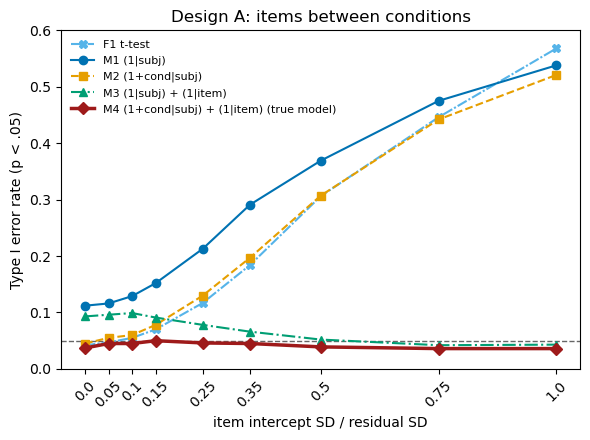

In [ ]:
fig_A = plot_design(t1_rates, "A", "Design A: items between conditions", "item intercept SD / residual SD")

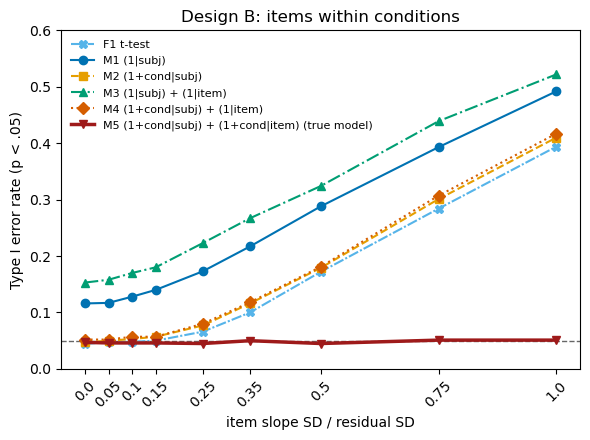

In [ ]:
fig_B = plot_design(t1_rates, "B", "Design B: items within conditions", "item slope SD / residual SD")